# Entregable II — Evaluación final, sensibilidad y reducción de dimensión

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante
aprendizaje supervisado.  
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.  
**Integrantes:** Mateo Upegui Borja, Juan P. Uribe González y Juan D. Rincón Bedoya.

¿Con qué fiabilidad identifica el modelo las sesiones que terminan en compra?
¿De qué variables depende, y se puede simplificar? Este notebook cierra el
trabajo. Parte de las particiones del 01 y de las cinco configuraciones que
eligió el 02, y las evalúa en la partición de prueba, que no intervino en
ninguna decisión.

Mantenemos la división de papeles del 02: las decisiones, como el umbral o el
número de componentes, se toman con entrenamiento y validación, y la prueba solo
describe su efecto. Los trabajos previos sobre esta base están resumidos en el
notebook 01. Sus cifras no se pueden comparar directamente con las nuestras,
porque cada trabajo usa otro balanceo y otra partición.

El notebook avanza en seis pasos:

1. Qué explica la selección del 02: la señal individual de las variables y el
   efecto de los hiperparámetros.
2. El rendimiento de las cinco familias en las tres particiones, con intervalos
   y comparaciones pareadas.
3. El efecto de elegir el umbral de decisión en validación.
4. La sensibilidad a `PageValues` y `SpecialDay`.
5. La reducción de dimensión con PCA y UMAP.
6. La discusión y las conclusiones.

Al ejecutarlo, el notebook vuelve a ajustar los cinco clasificadores. Las dos
búsquedas más costosas, la malla sin `PageValues` y el barrido de PCA y UMAP, se
leen de `resultados/evaluacion/`. Para repetirlas, basta cambiar a `True` las
banderas `REPETIR_SIN_PAGEVALUES` y `REPETIR_REDUCCION` de la celda siguiente.

In [1]:
import hashlib
from importlib.metadata import version
from itertools import combinations, product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import (
  ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
  precision_recall_curve, roc_curve,
)
from sklearn.model_selection import cross_val_score
from threadpoolctl import threadpool_limits

from shopytics.evaluation import comparar, intervalos, intervalos_cv, replicas
from shopytics.models import construir_modelos
from shopytics.presentation import FAMILIAS, MESES, PARAMETROS, PARTICIONES, legible, valor_legible
from shopytics.reduction import pipeline_reducido
from shopytics.search import mallas_ampliadas
from shopytics.training import buscar_configuraciones, evaluar, pliegues, validar_finalistas
from shopytics.utils import OBJETIVO, SEMILLA

# Con True se repiten las búsquedas en lugar de leer sus resultados guardados.
REPETIR_SIN_PAGEVALUES = False
REPETIR_REDUCCION = False


def mostrar(tabla):
  """Muestra la tabla con nombres legibles y columnas completas."""
  with pd.option_context("display.max_colwidth", None):
    display(legible(tabla))


def puntuar(modelo, datos):
  """Puntuación continua: probabilidad de compra o, en SVM, función de decisión."""
  if hasattr(modelo, "predict_proba"):
    return modelo.predict_proba(datos)[:, 1]
  return modelo.decision_function(datos)


def umbral_nativo(familia):
  """0 sobre la función de decisión de SVM y 0,5 sobre las probabilidades."""
  return 0 if familia == "SVM" else .5


def con_ic(valor, inferior, superior, signo=""):
  """Escribe una estimación con su intervalo, por ejemplo «0.7496 [0.7134, 0.7869]»."""
  return f"{valor:{signo}.4f} [{inferior:{signo}.4f}, {superior:{signo}.4f}]"


raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
datos = raiz / "data"
resultados = raiz / "resultados"
entrenamiento = resultados / "entrenamiento"
salida = resultados / "evaluacion"
salida.mkdir(exist_ok=True)

particiones = pd.read_pickle(datos / "dataset_particiones.pkl")
X = {p: df.drop(columns=OBJETIVO) for p, df in particiones.items()}
y = {p: df[OBJETIVO].astype(int) for p, df in particiones.items()}
tr, va, te = "entrenamiento", "validacion", "prueba"

mejores = pd.read_json(entrenamiento / "mejores_configuraciones.json").set_index("modelo")
familias = mejores.sort_values("AP", ascending=False).index

entorno = {
  "SHA-256 del CSV": hashlib.sha256((datos / "online_shoppers_intention.csv").read_bytes()).hexdigest(),
  "Semilla": SEMILLA,
  **{paquete: version(paquete)
    for paquete in ["numpy", "pandas", "scipy", "scikit-learn", "umap-learn", "numba"]},
}
mostrar(pd.Series(entorno, name="Valor"))

mostrar(pd.DataFrame([{
  "particion": p,
  "Sesiones": len(y[p]),
  "Compras": int(y[p].sum()),
  "Proporción de compras": round(y[p].mean(), 4)
} for p in y]).set_index("particion"))

mostrar(mejores.loc[familias, ["params", "AP_CV", "AP"]].round(4))

,Valor
SHA-256 del CSV,d8e130ba51532985f93281a73ce299e6ce150cb915769a7962a11e595eadd6a1
Semilla,42
numpy,2.3.1
pandas,2.3.1
scipy,1.16.3
scikit-learn,1.7.2
umap-learn,0.6.0
numba,0.68.1


,Sesiones,Compras,Proporción de compras
Partición,,,
Entrenamiento,7323,1145,0.1564
Validación,2441,381,0.1561
Prueba,2441,382,0.1565


,Configuración,AP-CV,AP
Modelo,,,
Random Forest,"Pesos de clase ninguno; Profundidad máxima 8; Variables por división 0,7; Mínimo de sesiones por hoja 20; log1p sí",0.7573,0.7414
MLP,"alpha 0,1; Capas ocultas (64,); Tasa de aprendizaje inicial 0,03; log1p sí",0.7375,0.7225
SVM,"C 30; Pesos de clase ninguno; gamma 0,01; Kernel RBF; log1p sí",0.7260,0.7054
k-NN,Vecinos (k) 81; Distancia euclídea; Ponderación distance; log1p sí,0.7172,0.7018
Regresión logística,"C 0,1; Pesos de clase ninguno; log1p sí",0.6897,0.6841


## 1. Qué explica la selección del 02

El primer gráfico recupera la señal individual que midió el notebook 01 para los
diez predictores más informativos. La barra es el AUC univariado y la anotación,
la información mutua (IM). El color indica la recomendación de ese análisis.

El segundo gráfico muestra cómo cambia el AP de validación cruzada con los
hiperparámetros principales de cada familia. Cada punto promedia todas las
configuraciones de la malla que comparten ese valor, y la barra de error es la
desviación entre los cinco pliegues. La línea gris es el AP sobre los mismos
datos de ajuste: la distancia entre ambas curvas indica cuánto sobreajusta cada
valor. En SVM solo se incluyen las configuraciones con kernel RBF.

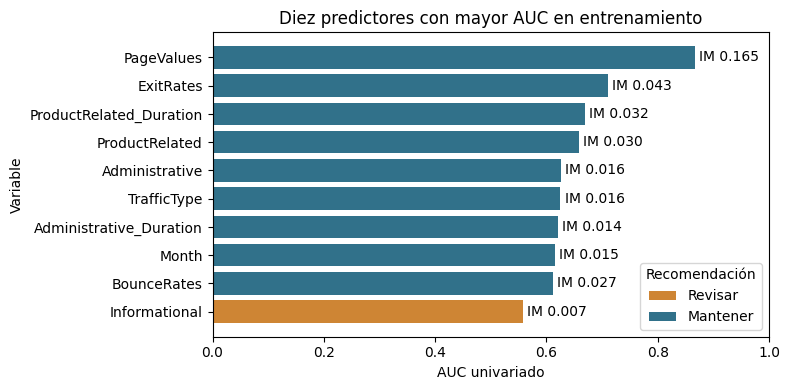

In [2]:
variables = pd.read_json(resultados / "variables" / "analisis_variables.json")

principales = (
  variables.nlargest(10, "auc_univariado")
    .sort_values("auc_univariado")
    .reset_index(drop=True)
)

colores = {"mantener": "#31718a", "revisar": "#ce8534", "eliminar o combinar": "#a5a5a5"}

fig, ax = plt.subplots(figsize=(8, 4))

for recomendacion, grupo in principales.groupby("recomendacion", sort=False):
  barras = ax.barh(
    grupo.index,
    grupo.auc_univariado,
    color=colores[recomendacion],
    label=recomendacion.capitalize()
    )

  ax.bar_label(
    barras,
    labels=[f"IM {im:.3f}" for im in grupo.informacion_mutua],
    padding=3
  )

ax.set(
  yticks=principales.index,
  yticklabels=principales.variable,
  xlim=(0, 1),
  xlabel="AUC univariado",
  ylabel="Variable",
  title="Diez predictores con mayor AUC en entrenamiento"
)

ax.legend(title="Recomendación", loc="lower right")
plt.tight_layout()
plt.show()

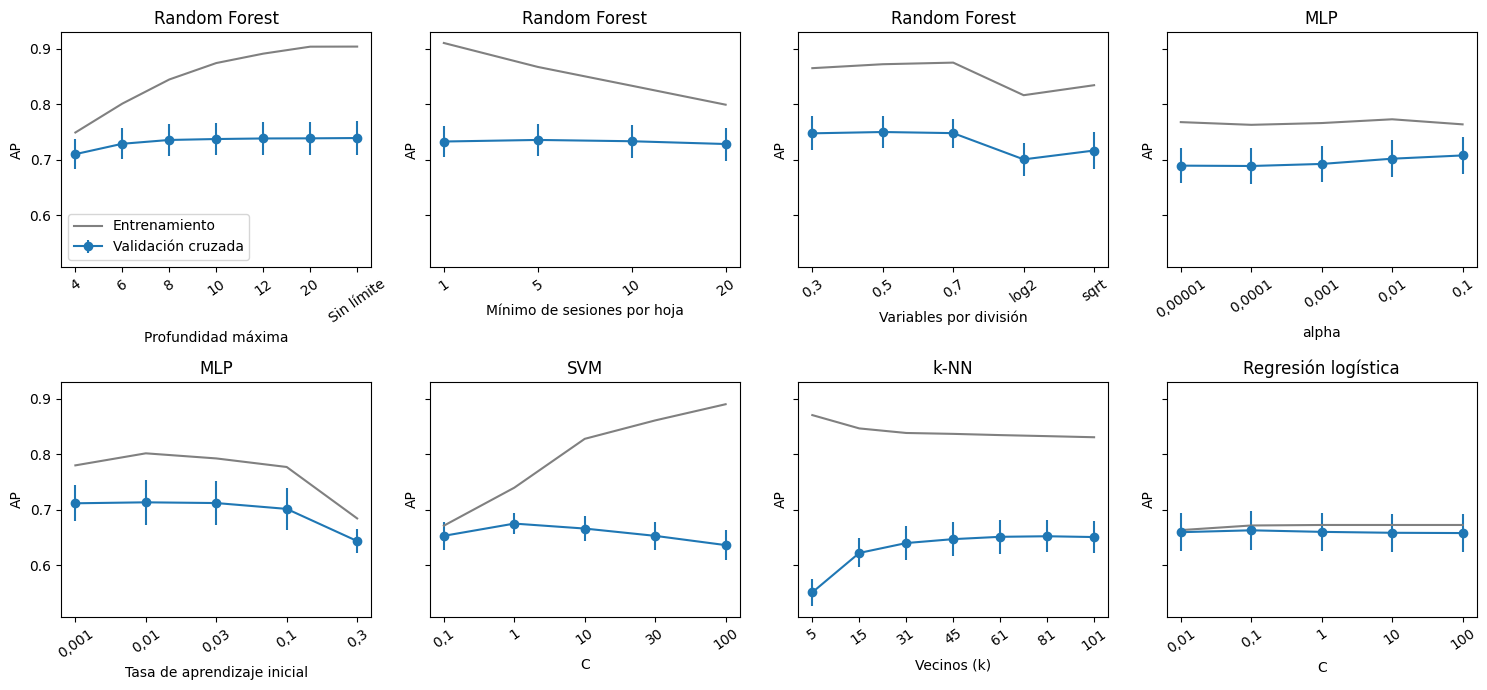

In [3]:
PANELES = [
  ("RandomForest", "max_depth"),
  ("RandomForest", "min_samples_leaf"),
  ("RandomForest", "max_features"),
  ("MLP", "alpha"),
  ("MLP", "learning_rate_init"),
  ("SVM", "C"),
  ("kNN", "n_neighbors"),
  ("Regresion_logistica", "C")
]

PLIEGUES_PRUEBA = [f"split{i}_test_score" for i in range(5)]
PLIEGUES_AJUSTE = [f"split{i}_train_score" for i in range(5)]


def ap_por_valor(familia, parametro):
  """AP medio por pliegue para cada valor del parámetro, en CV y en los datos de ajuste."""
  cv = pd.read_json(entrenamiento / "cv" / f"{familia}.json")
  params = pd.json_normalize(cv["params"])

  if familia == "SVM":
    cv = cv[params["clf__kernel"].eq("rbf")]

  grupos = cv.groupby(params["clf__" + parametro].fillna("Sin límite"))
  return grupos[PLIEGUES_PRUEBA].mean(), grupos[PLIEGUES_AJUSTE].mean()


fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharey=True)

for ax, (familia, parametro) in zip(axes.flat, PANELES):
  validacion, ajuste = ap_por_valor(familia, parametro)
  etiquetas = [valor_legible("clf__" + parametro, v) for v in validacion.index]

  ax.errorbar(
    etiquetas,
    validacion.mean(axis=1),
    yerr=validacion.std(axis=1),
    fmt="o-",
    label="Validación cruzada"
  )

  ax.plot(etiquetas, ajuste.mean(axis=1), color="gray", label="Entrenamiento")
  ax.set(title=FAMILIAS[familia], xlabel=PARAMETROS["clf__" + parametro], ylabel="AP")
  ax.tick_params(axis="x", rotation=35)

axes[0, 0].legend()
fig.tight_layout()
plt.show()

## 2. Rendimiento de las cinco familias

Ajustamos cada familia con su configuración del 02 sobre todo el entrenamiento y
la medimos en las tres particiones. AP y ROC-AUC usan la puntuación continua: la
probabilidad de compra o, en SVM, la función de decisión. Las demás métricas
usan el umbral nativo.

AP  ROC-AUC  Precisión  Recall      F1  \
Modelo              Partición                                                   
Random Forest       Entrenamiento  0.8284   0.9573     0.7977  0.6541  0.7188   
                    Validación     0.7414   0.9265     0.7025  0.5827  0.6370   
                    Prueba         0.7496   0.9302     0.7443  0.5942  0.6608   
MLP                 Entrenamiento  0.7798   0.9429     0.7500  0.6341  0.6872   
                    Validación     0.7225   0.9242     0.7161  0.5958  0.6504   
                    Prueba         0.7494   0.9284     0.7157  0.5864  0.6446   
SVM                 Entrenamiento  0.7986   0.9386     0.7745  0.6480  0.7057   
                    Validación     0.7054   0.9001     0.7013  0.5669  0.6270   
                    Prueba         0.7272   0.9034     0.7210  0.6021  0.6562   
k-NN                Entrenamiento  1.0000   1.0000     1.0000  1.0000  1.0000   
                    Validación     0.7018   0.9124     0.7266  0.4882  0.5840   
                    Prueba         0.6976   0.9075     0.7346  0.5000  0.5950   
Regresión logística Entrenamiento  0.6987   0.9194     0.7141  0.5520  0.6227   
                    Validación     0.6841   0.9123     0.7170  0.5853  0.6445   
                    Prueba         0.6956   0.9110     0.7143  0.5497  0.6213   

                                   Exactitud balanceada  Exactitud  
Modelo              Partición                                       
Random Forest       Entrenamiento                0.8117     0.9200  
                    Validación                   0.7685     0.8964  
                    Prueba                       0.7782     0.9045  
MLP                 Entrenamiento                0.7974     0.9097  
                    Validación                   0.7761     0.9000  
                    Prueba                       0.7716     0.8988  
SVM                 Entrenamiento                0.8065     0.9155  
                    Validación                   0.7611     0.8947  
                    Prueba                       0.7794     0.9013  
k-NN                Entrenamiento                1.0000     1.0000  
                    Validación                   0.7271     0.8914  
                    Prueba                       0.7332     0.8935  
Regresión logística Entrenamiento                0.7555     0.8954  
                    Validación                   0.7713     0.8992  
                    Prueba                       0.7545     0.8951

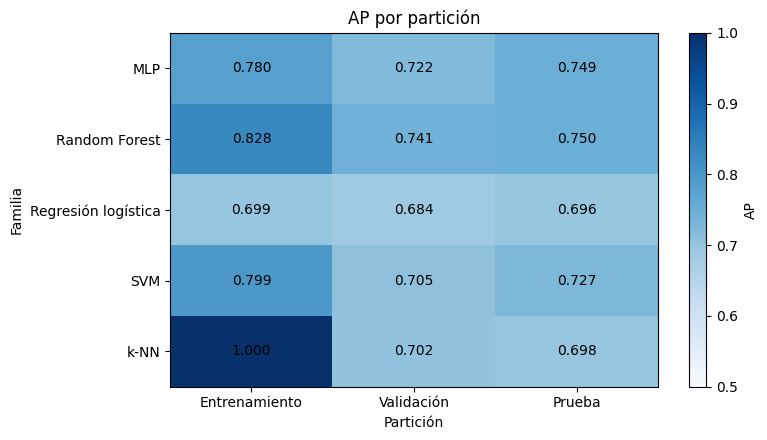

In [4]:
modelos = construir_modelos()
puntuaciones, filas = {}, []

with threadpool_limits(limits=1):
  for familia in familias:
    modelo = modelos[familia].set_params(**mejores.at[familia, "params"]).fit(X[tr], y[tr])

    for p in particiones:
      puntuaciones[familia, p] = puntuar(modelo, X[p])
      filas.append({"modelo": familia, "particion": p, **evaluar(modelo, X[p], y[p])})

metricas = pd.DataFrame(filas).set_index(["modelo", "particion"])
mostrar(metricas.round(4))

ap = metricas.AP.unstack()[[tr, va, te]]
fig, ax = plt.subplots(figsize=(8, 4.5))
imagen = ax.imshow(ap, cmap="Blues", vmin=.5, vmax=1, aspect="auto")
fig.colorbar(imagen, ax=ax, label="AP")

for (i, j), valor in np.ndenumerate(ap.to_numpy()):
  ax.text(j, i, f"{valor:.3f}", ha="center", va="center")

ax.set(
  xticks=range(3),
  xticklabels=[PARTICIONES[p] for p in ap.columns],
  yticks=range(len(ap)),
  yticklabels=[FAMILIAS[f] for f in ap.index],
  xlabel="Partición",
  ylabel="Familia",
  title="AP por partición"
)

plt.tight_layout()
plt.show()

Random Forest y la MLP obtienen la mayor AP en prueba (0,7496 y 0,7494),
seguidas de SVM (0,7272), k-NN (0,6976) y regresión logística (0,6956). El AP de
entrenamiento supera al de validación en todas las familias. El 1,0000 de k-NN
no indica sobreajuste: al ponderar por distancia, cada sesión de entrenamiento
se encuentra a sí misma como vecina más cercana. La regresión logística tiene la
brecha más estrecha (0,6987 frente a 0,6841). En cuatro familias el AP de prueba
es algo mayor que el de validación, una variación esperable entre dos
particiones de 2.441 sesiones.

La figura siguiente muestra las curvas precisión–recall y ROC de las cinco
familias en cada partición. En las curvas precisión–recall, la línea punteada
marca la proporción de compras, que es lo que obtendría un orden al azar; en las
ROC, la diagonal.

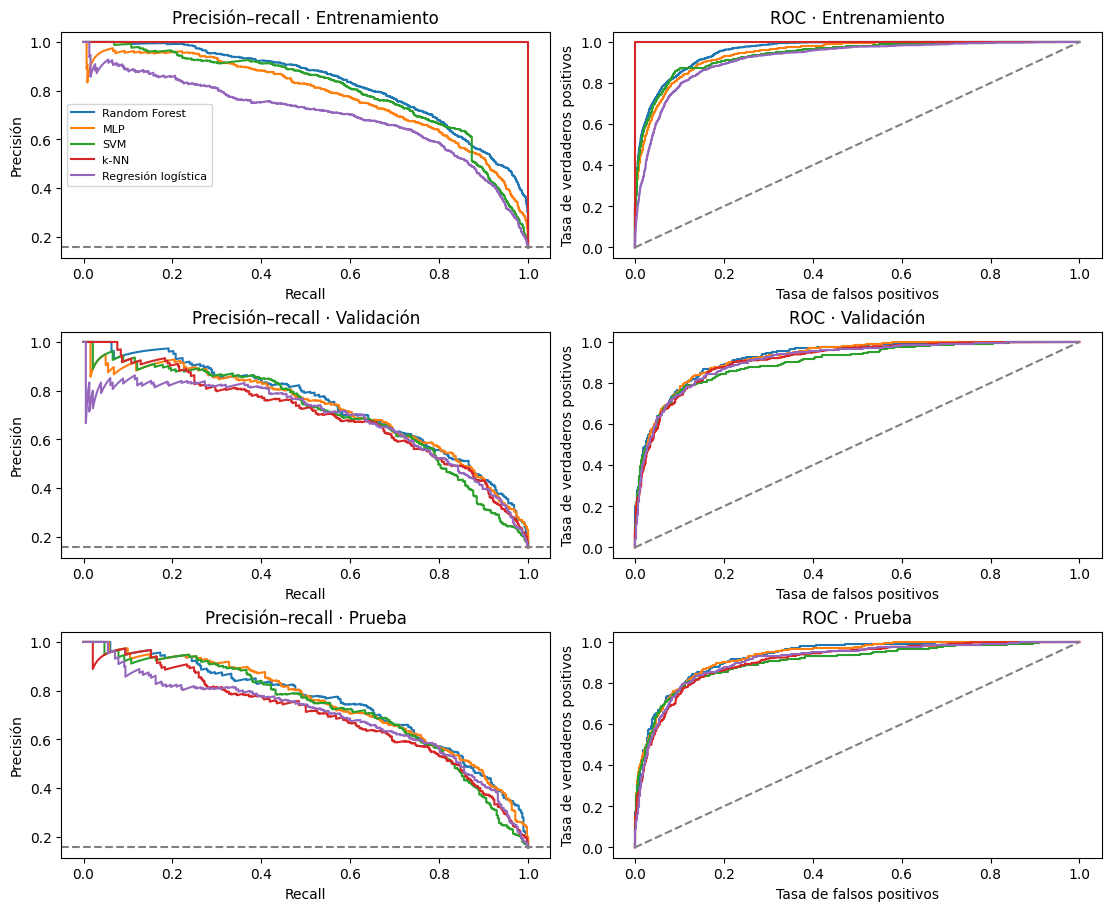

In [5]:
fig, axes = plt.subplots(len(particiones), 2, figsize=(11, 9), layout="constrained")

for p, (ax_pr, ax_roc) in zip(particiones, axes):
  for familia in familias:
    precision, recall, _ = precision_recall_curve(y[p], puntuaciones[familia, p])
    fpr, tpr, _ = roc_curve(y[p], puntuaciones[familia, p])
    ax_pr.plot(recall, precision, label=FAMILIAS[familia])
    ax_roc.plot(fpr, tpr)

  ax_pr.axhline(y[p].mean(), ls="--", color="gray")
  ax_roc.plot([0, 1], [0, 1], "--", color="gray")

  ax_pr.set(
    xlabel="Recall",
    ylabel="Precisión",
    title=f"Precisión–recall · {PARTICIONES[p]}"
  )
  
  ax_roc.set(
    xlabel="Tasa de falsos positivos",
    ylabel="Tasa de verdaderos positivos",
    title=f"ROC · {PARTICIONES[p]}"
  )

axes[0, 0].legend(fontsize=8)
plt.show()

### Intervalos y comparaciones pareadas

Medimos la incertidumbre de tres formas.

**Validación cruzada.** Con la métrica de los cinco pliegues, su media $\bar x$
y su desviación muestral $s$, el intervalo del 95 % para la media es

$$\bar x \pm t_{0{,}975;\,4}\,\frac{s}{\sqrt{5}}, \qquad t_{0{,}975;\,4} \approx 2{,}776 .$$

La media ± desviación describiría cuánto varían los pliegues, no cuánto se
conoce la media. El error estándar $s/\sqrt{5}$ sí mide eso, y la distribución
*t* con cuatro grados de libertad ensancha el intervalo para reflejar que $s$ se
estima con solo cinco valores.

**Particiones.** En entrenamiento, validación y prueba dejamos fijos el modelo y
sus puntuaciones, y remuestreamos las sesiones con el bootstrap (Efron, 1979).
En cada una de las $B = 2.000$ réplicas sorteamos con reemplazo, por separado,
tantas compras y tantas sesiones sin compra como tiene la partición, para
conservar la proporción de clases. Con eso recalculamos la métrica
$\hat\theta^{*}_b$. El intervalo va del percentil 2,5 al 97,5 de las réplicas:

$$\left[\hat\theta^{*}_{(2{,}5\,\%)},\ \hat\theta^{*}_{(97{,}5\,\%)}\right].$$

**Comparaciones pareadas.** Para comparar dos modelos A y B usamos las mismas
réplicas en ambos y calculamos la diferencia
$\Delta^{*}_b = \hat\theta^{*}_{A,b} - \hat\theta^{*}_{B,b}$. Su intervalo es el
de los percentiles 2,5 y 97,5 de esas diferencias. Como los dos modelos se miden
sobre las mismas sesiones, la variación que comparten se cancela, y el intervalo
es más estrecho que si comparáramos dos intervalos por separado. Si incluye el
cero, no detectamos diferencia; eso no prueba que los modelos sean iguales.
Ninguno de estos intervalos incluye la variación que introduciría reentrenar o
volver a seleccionar los modelos.

Las tablas siguientes muestran, en este orden, los intervalos de validación
cruzada para AP, ROC-AUC y F1; los intervalos de AP en cada partición; las
métricas de prueba con el umbral nativo, cada una con su intervalo bootstrap; y
las comparaciones pareadas de AP y ROC-AUC en prueba.

In [6]:
muestras = {
  (familia, p): replicas(
    y[p],
    puntuaciones[familia, p],
    umbral_nativo(familia)
  ) for familia in familias for p in particiones
}

with threadpool_limits(limits=1):
  ic_cv = pd.concat(
    [intervalos_cv(modelos[familia], X[tr], y[tr]).assign(modelo=familia) for familia in familias],
    ignore_index=True
  )

ic = pd.concat(
  [intervalos(muestra).assign(modelo=familia, particion=p) for (familia, p), muestra in muestras.items()],
  ignore_index=True
)

pares = pd.concat(
  [comparar(muestras[a, te], muestras[b, te]).assign(modelo_a=a, modelo_b=b) for a, b in combinations(familias, 2)],
  ignore_index=True
)

mostrar(ic_cv.set_index(["modelo", "metrica"]).round(4))
mostrar(
  ic.query("metrica == 'AP'")
    .set_index(["modelo", "particion"])
    .drop(columns="metrica")
    .round(4)
)

ic_prueba = ic.query("particion == @te").set_index(["modelo", "metrica"])
puntual = metricas.xs(te, level="particion")

METRICAS_PRUEBA = ["AP", "ROC_AUC", "F1", "precision", "recall", "balanced_accuracy"]

mostrar(
  pd.DataFrame(
    {m: [con_ic(puntual.at[f, m], *ic_prueba.loc[(f, m), ["ic_inferior", "ic_superior"]]) for f in familias] for m in METRICAS_PRUEBA},
    index=pd.Index(familias, name="modelo"),
  )
)

mostrar(pares.set_index(["modelo_a", "modelo_b", "metrica"]).round(4))

Pliegues   Media  Desviación  Error estándar  \
Modelo              Métrica                                                 
Random Forest       AP              5  0.7573      0.0262          0.0117   
                    ROC-AUC         5  0.9340      0.0076          0.0034   
                    F1              5  0.6649      0.0343          0.0153   
MLP                 AP              5  0.7375      0.0382          0.0171   
                    ROC-AUC         5  0.9280      0.0101          0.0045   
                    F1              5  0.6391      0.0555          0.0248   
SVM                 AP              5  0.7260      0.0393          0.0176   
                    ROC-AUC         5  0.9032      0.0193          0.0086   
                    F1              5  0.6580      0.0498          0.0223   
k-NN                AP              5  0.7172      0.0259          0.0116   
                    ROC-AUC         5  0.9180      0.0095          0.0043   
                    F1              5  0.5760      0.0515          0.0230   
Regresión logística AP              5  0.6897      0.0357          0.0160   
                    ROC-AUC         5  0.9158      0.0085          0.0038   
                    F1              5  0.6164      0.0297          0.0133   

                             IC inferior  IC superior  
Modelo              Métrica                            
Random Forest       AP            0.7248       0.7898  
                    ROC-AUC       0.9245       0.9435  
                    F1            0.6224       0.7074  
MLP                 AP            0.6901       0.7850  
                    ROC-AUC       0.9155       0.9406  
                    F1            0.5702       0.7079  
SVM                 AP            0.6772       0.7748  
                    ROC-AUC       0.8793       0.9271  
                    F1            0.5961       0.7198  
k-NN                AP            0.6850       0.7494  
                    ROC-AUC       0.9061       0.9298  
                    F1            0.5121       0.6399  
Regresión logística AP            0.6453       0.7341  
                    ROC-AUC       0.9052       0.9264  
                    F1            0.5796       0.6533

Media bootstrap  IC inferior  IC superior
Modelo              Partición                                               
Random Forest       Entrenamiento           0.8283       0.8105       0.8448
                    Validación              0.7427       0.7034       0.7786
                    Prueba                  0.7505       0.7134       0.7869
MLP                 Entrenamiento           0.7799       0.7562       0.8010
                    Validación              0.7240       0.6808       0.7653
                    Prueba                  0.7504       0.7127       0.7873
SVM                 Entrenamiento           0.7986       0.7767       0.8183
                    Validación              0.7072       0.6634       0.7490
                    Prueba                  0.7282       0.6864       0.7689
k-NN                Entrenamiento           1.0000       1.0000       1.0000
                    Validación              0.7029       0.6626       0.7433
                    Prueba                  0.6990       0.6561       0.7392
Regresión logística Entrenamiento           0.6992       0.6720       0.7251
                    Validación              0.6866       0.6392       0.7342
                    Prueba                  0.6975       0.6541       0.7396

,AP,ROC-AUC,F1,Precisión,Recall,Exactitud balanceada
Modelo,,,,,,
Random Forest,"0.7496 [0.7134, 0.7869]","0.9302 [0.9178, 0.9430]","0.6608 [0.6211, 0.6984]","0.7443 [0.7006, 0.7886]","0.5942 [0.5445, 0.6414]","0.7782 [0.7534, 0.8016]"
MLP,"0.7494 [0.7127, 0.7873]","0.9284 [0.9150, 0.9410]","0.6446 [0.6040, 0.6838]","0.7157 [0.6715, 0.7613]","0.5864 [0.5392, 0.6361]","0.7716 [0.7475, 0.7962]"
SVM,"0.7272 [0.6864, 0.7689]","0.9034 [0.8850, 0.9212]","0.6562 [0.6161, 0.6938]","0.7210 [0.6785, 0.7675]","0.6021 [0.5524, 0.6492]","0.7794 [0.7554, 0.8030]"
k-NN,"0.6976 [0.6561, 0.7392]","0.9075 [0.8923, 0.9232]","0.5950 [0.5507, 0.6379]","0.7346 [0.6875, 0.7836]","0.5000 [0.4503, 0.5497]","0.7332 [0.7077, 0.7580]"
Regresión logística,"0.6956 [0.6541, 0.7396]","0.9110 [0.8950, 0.9272]","0.6213 [0.5778, 0.6647]","0.7143 [0.6688, 0.7621]","0.5497 [0.5000, 0.5995]","0.7545 [0.7288, 0.7807]"


Media bootstrap  IC inferior  \
Modelo A      Modelo B            Métrica                                 
Random Forest MLP                 AP                0.0002      -0.0190   
                                  ROC-AUC           0.0019      -0.0036   
              SVM                 AP                0.0223       0.0001   
                                  ROC-AUC           0.0270       0.0144   
              k-NN                AP                0.0515       0.0304   
                                  ROC-AUC           0.0226       0.0151   
              Regresión logística AP                0.0531       0.0244   
                                  ROC-AUC           0.0191       0.0107   
MLP           SVM                 AP                0.0221       0.0068   
                                  ROC-AUC           0.0251       0.0130   
              k-NN                AP                0.0514       0.0293   
                                  ROC-AUC           0.0207       0.0130   
              Regresión logística AP                0.0529       0.0268   
                                  ROC-AUC           0.0172       0.0091   
SVM           k-NN                AP                0.0292       0.0036   
                                  ROC-AUC          -0.0044      -0.0200   
              Regresión logística AP                0.0308       0.0051   
                                  ROC-AUC          -0.0079      -0.0224   
k-NN          Regresión logística AP                0.0015      -0.0272   
                                  ROC-AUC          -0.0035      -0.0141   

                                           IC superior  Diferencia  Réplicas  
Modelo A      Modelo B            Métrica                                     
Random Forest MLP                 AP            0.0190      0.0002      2000  
                                  ROC-AUC       0.0075      0.0018      2000  
              SVM                 AP            0.0450      0.0224      2000  
                                  ROC-AUC       0.0406      0.0268      2000  
              k-NN                AP            0.0737      0.0520      2000  
                                  ROC-AUC       0.0307      0.0227      2000  
              Regresión logística AP            0.0812      0.0539      2000  
                                  ROC-AUC       0.0289      0.0192      2000  
MLP           SVM                 AP            0.0379      0.0222      2000  
                                  ROC-AUC       0.0382      0.0249      2000  
              k-NN                AP            0.0735      0.0518      2000  
                                  ROC-AUC       0.0295      0.0209      2000  
              Regresión logística AP            0.0801      0.0537      2000  
                                  ROC-AUC       0.0261      0.0174      2000  
SVM           k-NN                AP            0.0543      0.0296      2000  
                                  ROC-AUC       0.0102     -0.0041      2000  
              Regresión logística AP            0.0567      0.0316      2000  
                                  ROC-AUC       0.0062     -0.0076      2000  
k-NN          Regresión logística AP            0.0298      0.0019      2000  
                                  ROC-AUC       0.0069     -0.0035      2000

En prueba, Random Forest y la MLP no se distinguen: la diferencia pareada de AP
es +0,0002 (IC [−0,0190; 0,0190]) y la de ROC-AUC, +0,0018 (IC [−0,0036;
0,0075]). Las dos superan en AP a las otras tres familias, con intervalos que
excluyen el cero. El margen de Random Forest frente a SVM es estrecho: el límite
inferior de su intervalo es 0,0001. k-NN y la regresión logística tampoco se
distinguen entre sí en AP.

## 3. ¿Qué cambia al elegir el umbral por F1?

El umbral nativo no tiene por qué ser el mejor para una clase minoritaria. Para
cada familia buscamos en validación el umbral que maximiza F1, el menor en caso
de empate, y lo aplicamos una sola vez en prueba.

La primera tabla compara las dos reglas en prueba. Con el umbral fijo, el número
de compras detectadas sigue una binomial dentro de las compras, y el de falsas
alarmas, otra dentro de las sesiones sin compra. Los intervalos salen de
remuestrear esas dos binomiales. La segunda tabla da las matrices de confusión
con el umbral nativo en las tres particiones, y la figura compara las dos reglas
en prueba para las dos mejores familias.

Umbral                precisión  \
Modelo              Regla                                                 
Random Forest       Nativo            0.500000  0.7443 [0.6994, 0.7873]   
                    F1 en validación  0.319528  0.6505 [0.6130, 0.6889]   
MLP                 Nativo            0.500000  0.7157 [0.6711, 0.7615]   
                    F1 en validación  0.433714  0.6818 [0.6411, 0.7225]   
SVM                 Nativo            0.000000  0.7210 [0.6774, 0.7662]   
                    F1 en validación -0.697044  0.6345 [0.5982, 0.6723]   
k-NN                Nativo            0.500000  0.7346 [0.6873, 0.7842]   
                    F1 en validación  0.398862  0.6547 [0.6126, 0.6970]   
Regresión logística Nativo            0.500000  0.7143 [0.6698, 0.7607]   
                    F1 en validación  0.317197  0.6337 [0.5939, 0.6727]   

                                                       Recall  \
Modelo              Regla                                       
Random Forest       Nativo            0.5942 [0.5471, 0.6440]   
                    F1 en validación  0.7356 [0.6911, 0.7776]   
MLP                 Nativo            0.5864 [0.5366, 0.6361]   
                    F1 en validación  0.6675 [0.6230, 0.7147]   
SVM                 Nativo            0.6021 [0.5550, 0.6518]   
                    F1 en validación  0.7225 [0.6780, 0.7670]   
k-NN                Nativo            0.5000 [0.4503, 0.5497]   
                    F1 en validación  0.6204 [0.5732, 0.6702]   
Regresión logística Nativo            0.5497 [0.5000, 0.5995]   
                    F1 en validación  0.6885 [0.6440, 0.7356]   

                                         exactitud balanceada  \
Modelo              Regla                                       
Random Forest       Nativo            0.7782 [0.7541, 0.8040]   
                    F1 en validación  0.8311 [0.8087, 0.8532]   
MLP                 Nativo            0.7716 [0.7469, 0.7973]   
                    F1 en validación  0.8049 [0.7819, 0.8293]   
SVM                 Nativo            0.7794 [0.7548, 0.8044]   
                    F1 en validación  0.8226 [0.7997, 0.8459]   
k-NN                Nativo            0.7332 [0.7084, 0.7580]   
                    F1 en validación  0.7799 [0.7554, 0.8051]   
Regresión logística Nativo            0.7545 [0.7297, 0.7804]   
                    F1 en validación  0.8073 [0.7835, 0.8313]   

                                                           F1  
Modelo              Regla                                      
Random Forest       Nativo            0.6608 [0.6195, 0.7003]  
                    F1 en validación  0.6904 [0.6569, 0.7236]  
MLP                 Nativo            0.6446 [0.6030, 0.6865]  
                    F1 en validación  0.6746 [0.6381, 0.7110]  
SVM                 Nativo            0.6562 [0.6154, 0.6960]  
                    F1 en validación  0.6756 [0.6416, 0.7091]  
k-NN                Nativo            0.5950 [0.5508, 0.6373]  
                    F1 en validación  0.6371 [0.5987, 0.6756]  
Regresión logística Nativo            0.6213 [0.5786, 0.6638]  
                    F1 en validación  0.6600 [0.6239, 0.6954]

VN   FP   FN    VP
Modelo              Partición                          
Random Forest       Entrenamiento  5988  190  396   749
                    Validación     1966   94  159   222
                    Prueba         1981   78  155   227
MLP                 Entrenamiento  5936  242  419   726
                    Validación     1970   90  154   227
                    Prueba         1970   89  158   224
SVM                 Entrenamiento  5962  216  403   742
                    Validación     1968   92  165   216
                    Prueba         1970   89  152   230
k-NN                Entrenamiento  6178    0    0  1145
                    Validación     1990   70  195   186
                    Prueba         1990   69  191   191
Regresión logística Entrenamiento  5925  253  513   632
                    Validación     1972   88  158   223
                    Prueba         1975   84  172   210

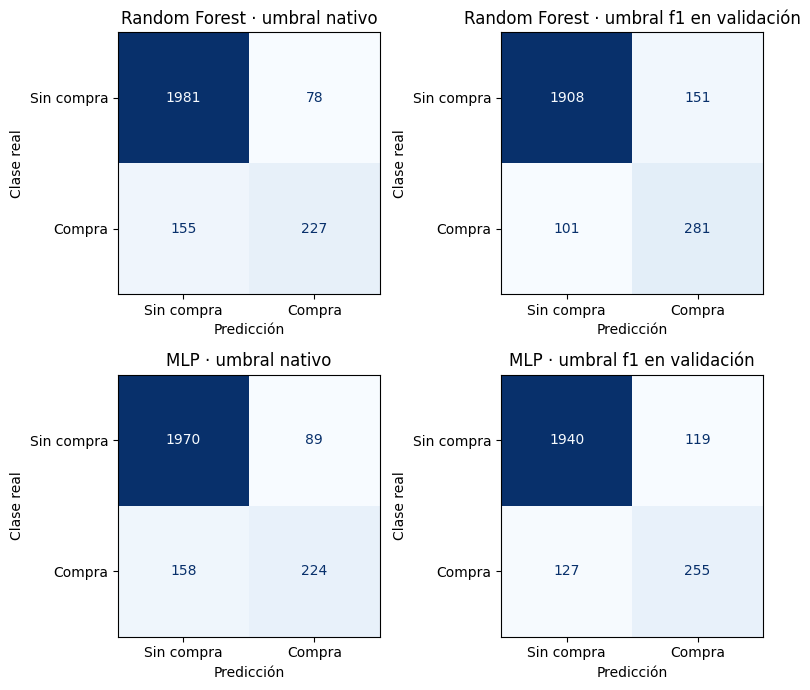

In [7]:
def resumen_umbral(y_real, scores, umbral, n_boot=2000):
    """Precisión, recall, exactitud balanceada y F1 con su intervalo del 95 %.

    Con el umbral fijo, los aciertos dentro de las compras y las falsas alarmas
    dentro de las sesiones sin compra siguen binomiales que se remuestrean por
    separado.
    """
    vn, fp, fn, vp = confusion_matrix(y_real, scores >= umbral, labels=[0, 1]).ravel()
    positivos, negativos = vp + fn, vn + fp
    rng = np.random.default_rng(SEMILLA)
    aciertos = np.r_[vp, rng.binomial(positivos, vp / positivos, n_boot)]
    falsas = np.r_[fp, rng.binomial(negativos, fp / negativos, n_boot)]
    predichos = aciertos + falsas
    precision = np.divide(aciertos, predichos, out=np.zeros(len(aciertos)), where=predichos > 0)
    recall = aciertos / positivos
    especificidad = 1 - falsas / negativos
    medidas = {"precisión": precision, "recall": recall,
               "exactitud balanceada": (recall + especificidad) / 2,
               "F1": 2 * aciertos / (predichos + positivos)}
    return {nombre: con_ic(v[0], *np.quantile(v[1:], [.025, .975])) for nombre, v in medidas.items()}


def umbral_f1(y_real, scores):
    """Umbral que maximiza F1; ante empates, el menor."""
    precision, recall, cortes = precision_recall_curve(y_real, scores)
    f1 = 2 * precision * recall / np.maximum(precision + recall, np.finfo(float).eps)
    return cortes[f1[:-1].argmax()]


def conteos(y_real, scores, umbral):
    vn, fp, fn, vp = confusion_matrix(y_real, scores >= umbral, labels=[0, 1]).ravel()
    return {"VN": vn, "FP": fp, "FN": fn, "VP": vp}


umbrales = {familia: umbral_f1(y[va], puntuaciones[familia, va]) for familia in familias}
reglas = {familia: [("Nativo", umbral_nativo(familia)), ("F1 en validación", umbrales[familia])]
          for familia in familias}
mostrar(pd.DataFrame([{"modelo": familia, "regla": regla, "umbral": corte,
                       **resumen_umbral(y[te], puntuaciones[familia, te], corte)}
                      for familia in familias for regla, corte in reglas[familia]])
        .set_index(["modelo", "regla"]))
mostrar(pd.DataFrame([{"modelo": familia, "particion": p,
                       **conteos(y[p], puntuaciones[familia, p], umbral_nativo(familia))}
                      for familia in familias for p in particiones])
        .set_index(["modelo", "particion"]))

fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for familia, fila in zip(familias[:2], axes):
    for ax, (regla, corte) in zip(fila, reglas[familia]):
        ConfusionMatrixDisplay.from_predictions(
            y[te], puntuaciones[familia, te] >= corte, display_labels=["Sin compra", "Compra"],
            colorbar=False, ax=ax, cmap="Blues")
        ax.set(title=f"{FAMILIAS[familia]} · umbral {regla.lower()}", xlabel="Predicción",
               ylabel="Clase real")
plt.tight_layout()
plt.show()

El umbral elegido por F1 mejora el F1 y el recall de las cinco familias a cambio
de precisión. En Random Forest, el F1 pasa de 0,6608 a 0,6904 y el recall de
0,5942 a 0,7356, mientras la precisión baja de 0,7443 a 0,6505. En prueba eso
significa 54 compras más detectadas (de 227 a 281) y 73 falsas alarmas más (de
78 a 151). Que convenga o no depende del costo de contactar a un visitante que
no iba a comprar frente al valor de recuperar una compra.

## 4. Sensibilidad a PageValues y SpecialDay

`PageValues` es la variable más informativa y la menos disponible: solo se
conoce completa al cierre de la sesión. Para medir cuánto depende el modelo de
ella, repetimos el protocolo completo del 02 sin esa columna. Cada familia
vuelve a recorrer su malla y elige, por AP de validación, entre sus tres mejores
candidatos de validación cruzada. Por defecto, la celda lee los quince
finalistas guardados de esa búsqueda.

In [8]:
ruta_sin_pv = salida / "finalistas_sin_pagevalues.json"
if REPETIR_SIN_PAGEVALUES:
    _, mallas = mallas_ampliadas()
    with threadpool_limits(limits=1):
        finalistas_sin_pv = pd.concat(
            [validar_finalistas(modelo, buscar_configuraciones(modelo, mallas[familia], X[tr], y[tr]),
                                X[tr], y[tr], X[va], y[va]).assign(modelo=familia)
             for familia, modelo in construir_modelos(incluir_pagevalues=False).items()],
            ignore_index=True,
        )
    finalistas_sin_pv.to_json(ruta_sin_pv, orient="records", indent=2, double_precision=15)
else:
    finalistas_sin_pv = pd.read_json(ruta_sin_pv, precise_float=True)

# Mejor finalista de cada familia sin PageValues, frente a la configuración del 02.
sin_pv = finalistas_sin_pv.loc[finalistas_sin_pv.groupby("modelo").AP.idxmax()].set_index("modelo")
pv = pd.DataFrame({"AP_con": mejores.AP, "AP_sin": sin_pv.AP}).loc[familias]
pv["delta_con_menos_sin"] = pv.AP_con - pv.AP_sin
pv["ROC_AUC_sin"] = sin_pv.ROC_AUC
pv["params"] = sin_pv.params
mostrar(pv.round(4))

,AP con la variable,AP sin la variable,ΔAP (con − sin),ROC-AUC sin la variable,Configuración
Modelo,,,,,
Random Forest,0.7414,0.3848,0.3566,0.7847,Pesos de clase balanced; Profundidad máxima sin límite; Variables por división sqrt; Mínimo de sesiones por hoja 5; log1p sí
MLP,0.7225,0.3532,0.3693,0.7653,"alpha 0,1; Capas ocultas (64,); Tasa de aprendizaje inicial 0,01; log1p no"
SVM,0.7054,0.3403,0.3652,0.7685,"C 1; Pesos de clase balanced; gamma 0,01; Kernel RBF; log1p sí"
k-NN,0.7018,0.3477,0.3541,0.7615,Vecinos (k) 101; Distancia Manhattan; Ponderación distance; log1p sí
Regresión logística,0.6841,0.3345,0.3496,0.7616,"C 0,1; Pesos de clase ninguno; log1p sí"


Sin `PageValues`, el AP de validación cae a entre 0,3345 y 0,3848, una pérdida
de 0,35 a 0,37 en todas las familias, aun con los hiperparámetros reajustados.
El ROC-AUC se mantiene entre 0,76 y 0,78, así que las demás variables todavía
ordenan algo, pero el modelo pierde cerca de la mitad de su AP. Usarlo durante
la navegación, antes de conocer `PageValues`, implicaría asumir esa pérdida.

`SpecialDay` plantea dos preguntas distintas: si aporta algo y si conviene
codificarla de otra forma. Para separarlas dejamos fija la configuración del 02
y medimos dos cambios: retirar la columna y pasar de la escala numérica de
cercanía a una codificación one-hot de sus seis niveles. No probamos una
codificación ordinal porque, al estandarizarla, los seis niveles equidistantes
quedan exactamente igual que la escala numérica.

Completamos la comparación con el AP mensual del ganador en validación, para ver
si el desempeño cambia con la época del año.

In [9]:
def ap_validacion(modelo):
    """Ajusta el modelo en entrenamiento y devuelve su AP de validación."""
    modelo.fit(X[tr], y[tr])
    return average_precision_score(y[va], puntuar(modelo, X[va]))


sin_specialday = construir_modelos(incluir_specialday=False)
specialday_onehot = construir_modelos(codificar_specialday="onehot")
ap_cv = ic_cv.query("metrica == 'AP'").set_index("modelo").media

filas = []
with threadpool_limits(limits=1):
    for familia in familias:
        params = mejores.at[familia, "params"]
        sin = sin_specialday[familia].set_params(**params)
        onehot = specialday_onehot[familia].set_params(**params)
        filas.append({
            "modelo": familia,
            "numérico": metricas.at[(familia, va), "AP"],
            "sin": ap_validacion(sin),
            "onehot": ap_validacion(onehot),
            "AP_CV_numerico": ap_cv[familia],
            "AP_CV_onehot": cross_val_score(onehot, X[tr], y[tr], cv=pliegues(),
                                            scoring="average_precision", error_score="raise").mean(),
        })
sd = pd.DataFrame(filas).set_index("modelo")
sd["con_menos_sin"] = sd["numérico"] - sd["sin"]
sd["onehot_menos_numérico"] = sd["onehot"] - sd["numérico"]
mostrar(sd.round(4))

# AP mensual del ganador en validación, en orden de calendario.
ganador = familias[0]
sesiones_va = pd.DataFrame({"mes": X[va]["Month"], "compra": y[va], "score": puntuaciones[ganador, va]})
por_mes = sesiones_va.groupby("mes").agg(sesiones=("compra", "size"), compras=("compra", "sum"))
por_mes["AP"] = [average_precision_score(g.compra, g.score) if g.compra.any() else np.nan
                 for _, g in sesiones_va.groupby("mes")]
por_mes = por_mes.reindex([m for m in MESES if m in por_mes.index]).rename(index=MESES)
mostrar(por_mes.round(4))

,AP numérico,AP sin SpecialDay,AP one-hot,AP-CV numérico,AP-CV one-hot,ΔAP (con − sin),ΔAP (one-hot − numérico)
Modelo,,,,,,,
Random Forest,0.7414,0.7418,0.7418,0.7573,0.7556,-0.0004,0.0004
MLP,0.7225,0.7181,0.7322,0.7375,0.7365,0.0044,0.0097
SVM,0.7054,0.7040,0.6988,0.7260,0.7287,0.0014,-0.0066
k-NN,0.7018,0.7066,0.7065,0.7172,0.7216,-0.0048,0.0046
Regresión logística,0.6841,0.6845,0.6835,0.6897,0.6907,-0.0004,-0.0006


,Sesiones,Compras,AP
Mes,,,
Febrero,37,0,NaN
Marzo,359,38,0.7853
Mayo,663,74,0.8769
Junio,58,7,0.6900
Julio,96,15,0.5983
Agosto,76,8,0.5680
Septiembre,87,17,0.8390
Octubre,98,15,0.5891
Noviembre,633,166,0.6826


Retirar `SpecialDay` cambia el AP de validación entre −0,0044 y +0,0048, y
pasarla a one-hot, entre −0,0066 y +0,0097, sin un signo consistente entre
familias. En validación cruzada los cambios son igual de pequeños. La variable
casi no aporta, en línea con su AUC individual de 0,539.

El AP mensual varía mucho más: de 0,57 en agosto a 0,88 en mayo. Las
estimaciones son poco fiables en los meses con pocas compras, y en febrero la
partición de validación no tiene ninguna.

### Ablación con hiperparámetros fijos

La búsqueda sin `PageValues` reajusta los hiperparámetros, así que mezcla dos
efectos. Para separarlos retiramos `PageValues` y, por separado, `SpecialDay`
del ganador del 02 manteniendo su configuración, y lo medimos en entrenamiento y
validación.

In [10]:
filas = []
with threadpool_limits(limits=1):
    for variable, opcion in [("PageValues", "incluir_pagevalues"), ("SpecialDay", "incluir_specialday")]:
        modelo = construir_modelos(**{opcion: False})[ganador].set_params(**mejores.at[ganador, "params"])
        modelo.fit(X[tr], y[tr])
        filas += [{"variable": variable, "particion": p, **evaluar(modelo, X[p], y[p])} for p in (tr, va)]
mostrar(pd.DataFrame(filas).set_index(["variable", "particion"]).round(4))

AP  ROC-AUC  Precisión  Recall      F1  \
Variable   Partición                                                   
PageValues Entrenamiento  0.5214   0.8578     0.7680  0.1214  0.2097   
           Validación     0.3785   0.7840     0.4462  0.0761  0.1300   
SpecialDay Entrenamiento  0.8279   0.9571     0.8006  0.6594  0.7232   
           Validación     0.7418   0.9271     0.7111  0.5879  0.6437   

                          Exactitud balanceada  Exactitud  
Variable   Partición                                       
PageValues Entrenamiento                0.5573     0.8569  
           Validación                   0.5293     0.8410  
SpecialDay Entrenamiento                0.8145     0.9211  
           Validación                   0.7719     0.8984

Con la configuración fija, Random Forest sin `PageValues` obtiene un AP de
validación de 0,3785, apenas por debajo del 0,3848 que logra al reajustar la
malla: casi toda la pérdida viene de la variable, no de los hiperparámetros. Con
el umbral nativo, el modelo casi deja de detectar compras (recall de 0,0761 en
validación). Sin `SpecialDay`, el AP de validación queda en 0,7418,
prácticamente igual que con ella (0,7414).

## 5. Reducción de dimensión con PCA y UMAP

¿Se puede describir cada sesión con menos dimensiones sin perder capacidad
predictiva? Probamos dos reductores con las dos familias mejor clasificadas en
validación, Random Forest y la MLP. Después del preprocesamiento, la base tiene
73 columnas. PCA busca las direcciones lineales de mayor varianza, y UMAP
(McInnes et al., 2018) busca una representación de menor dimensión que conserve
las vecindades entre sesiones. Ninguno de los dos usa la etiqueta. Cada
candidato es un pipeline completo, de modo que la validación cruzada ajusta el
preprocesador y el reductor dentro de cada pliegue.

Para PCA probamos 5, 10, 15, 20, 28, 35 y 45 componentes, además del número que
retiene el 95 % de la varianza, que puede cambiar de un ajuste a otro. Para UMAP
probamos 2, 5, 10, 15 y 20 dimensiones con 15, 30 y 50 vecinos, y dejamos
`min_dist` en su valor por defecto.

In [11]:
# Dimensión de la base: columnas que produce el preprocesador.
n_base = len(modelos[familias[0]]["pre"].get_feature_names_out())
CANDIDATOS_REDUCCION = (
    [("PCA", n, None) for n in [5, 10, 15, 20, 28, 35, 45, .95]]
    + [("UMAP", n, k) for n, k in product([2, 5, 10, 15, 20], [15, 30, 50])]
)


def evaluar_reduccion(familia, metodo, n, vecinos):
    """AP de CV y de validación de la familia con un reductor delante del clasificador."""
    pipe = pipeline_reducido(modelos[familia], metodo, n, vecinos)
    folds = cross_val_score(pipe, X[tr], y[tr], scoring="average_precision", cv=pliegues(),
                            error_score="raise")
    pipe.fit(X[tr], y[tr])
    return {
        "modelo": familia, "metodo": metodo, "dimensiones_solicitadas": n,
        "componentes": pipe["reduccion"].n_components_ if metodo == "PCA" else n,
        "vecinos": vecinos, "AP_CV": folds.mean(), "std_CV": folds.std(),
        "AP": average_precision_score(y[va], puntuar(pipe, X[va])),
    }


if REPETIR_REDUCCION:
    with threadpool_limits(limits=1):
        barrido = pd.DataFrame([evaluar_reduccion(familia, *candidato)
                                for familia in familias[:2] for candidato in CANDIDATOS_REDUCCION])
    barrido.to_pickle(salida / "barrido_reduccion.pkl")
else:
    barrido = pd.read_pickle(salida / "barrido_reduccion.pkl")


def elegir_1se(grupo):
    """Menor dimensión cuyo AP de validación queda a un error estándar del mejor.

    Ante empates de dimensión prefiere un número fijo de componentes a la
    fracción de varianza, y después el mayor AP.
    """
    grupo = grupo.assign(fraccion=grupo.dimensiones_solicitadas < 1)
    mejor = grupo.sort_values(["AP", "componentes", "fraccion"], ascending=[False, True, True]).iloc[0]
    corte = mejor.AP - mejor.std_CV / np.sqrt(5)
    elegibles = grupo[grupo.AP >= corte - 1e-12]
    return elegibles.sort_values(["componentes", "fraccion", "AP"], ascending=[True, True, False]).iloc[0]


elegidos = pd.DataFrame([elegir_1se(grupo) for _, grupo in barrido.groupby(["modelo", "metodo"])])
elegidos["reduccion"] = (100 * (1 - elegidos.componentes / n_base)).round(1)
mostrar(elegidos.astype({"componentes": int}).set_index(["modelo", "metodo"])
        [["componentes", "vecinos", "reduccion", "AP_CV", "AP"]].round(4))

Componentes  Vecinos  Reducción (%)   AP-CV      AP
Modelo        Método                                                     
MLP           PCA              15      NaN           79.5  0.7368  0.7219
              UMAP              5     30.0           93.2  0.6739  0.6484
Random Forest PCA              10      NaN           86.3  0.7198  0.7074
              UMAP             15     50.0           79.5  0.6980  0.6959

Para elegir el número de componentes usamos la regla de un error estándar (1-SE;
Chen y Yang, 2021). Partimos del candidato con mayor AP de validación y
consideramos elegibles todos los que quedan a menos de un error estándar entre
pliegues de él, $s_{CV}/\sqrt{5}$. Entre los elegibles nos quedamos con el de
menor dimensión. La regla importa aquí porque retener el 95 % de la varianza
exige 28 componentes, más que los 17 predictores originales. La tabla anterior
muestra las variantes elegidas: 10 componentes de PCA para Random Forest y 15
para la MLP, y 15 y 5 dimensiones de UMAP.

La celda siguiente ajusta en entrenamiento las variantes elegidas y una
proyección UMAP de dos dimensiones, que solo sirve para visualizar. La figura
muestra, para cada familia, la varianza acumulada de PCA, el AP de validación
frente a la dimensión de PCA y de UMAP, con la variante elegida marcada con una
estrella, y la proyección UMAP 2D de las sesiones de prueba.

In [12]:
# Variantes que se evalúan en prueba: las elegidas por la regla 1-SE y UMAP 2D
# con 15 vecinos para la proyección.
columnas = ["modelo", "metodo", "dimensiones_solicitadas", "vecinos", "componentes", "AP"]
umap_2d = barrido.query("metodo == 'UMAP' and componentes == 2 and vecinos == 15")
ajustes = (pd.concat([elegidos[columnas], umap_2d[columnas].assign(metodo="UMAP2D")])
           .rename(columns={"AP": "AP_validacion"}))

varianzas, proyecciones, muestras_reducidas = [], [], {}
with threadpool_limits(limits=1):
    for familia in familias[:2]:
        pca = PCA(svd_solver="full").fit(modelos[familia]["pre"].transform(X[tr]))
        varianzas.append(pd.DataFrame({
            "modelo": familia,
            "componente": np.arange(1, pca.n_components_ + 1),
            "varianza_acumulada": pca.explained_variance_ratio_.cumsum(),
        }))
    for v in ajustes.itertuples():
        metodo = "UMAP" if v.metodo == "UMAP2D" else v.metodo
        pipe = pipeline_reducido(modelos[v.modelo], metodo, v.dimensiones_solicitadas, v.vecinos)
        pipe.fit(X[tr], y[tr])
        muestras_reducidas[v.modelo, v.metodo] = replicas(y[te], puntuar(pipe, X[te]),
                                                          umbral_nativo(v.modelo))
        if v.metodo == "UMAP2D":
            xy = pipe[:-1].transform(X[te])
            proyecciones.append(pd.DataFrame({"modelo": v.modelo, "x": xy[:, 0], "y": xy[:, 1],
                                              "compra": y[te].to_numpy()}))
varianza = pd.concat(varianzas, ignore_index=True)
proyeccion = pd.concat(proyecciones, ignore_index=True)

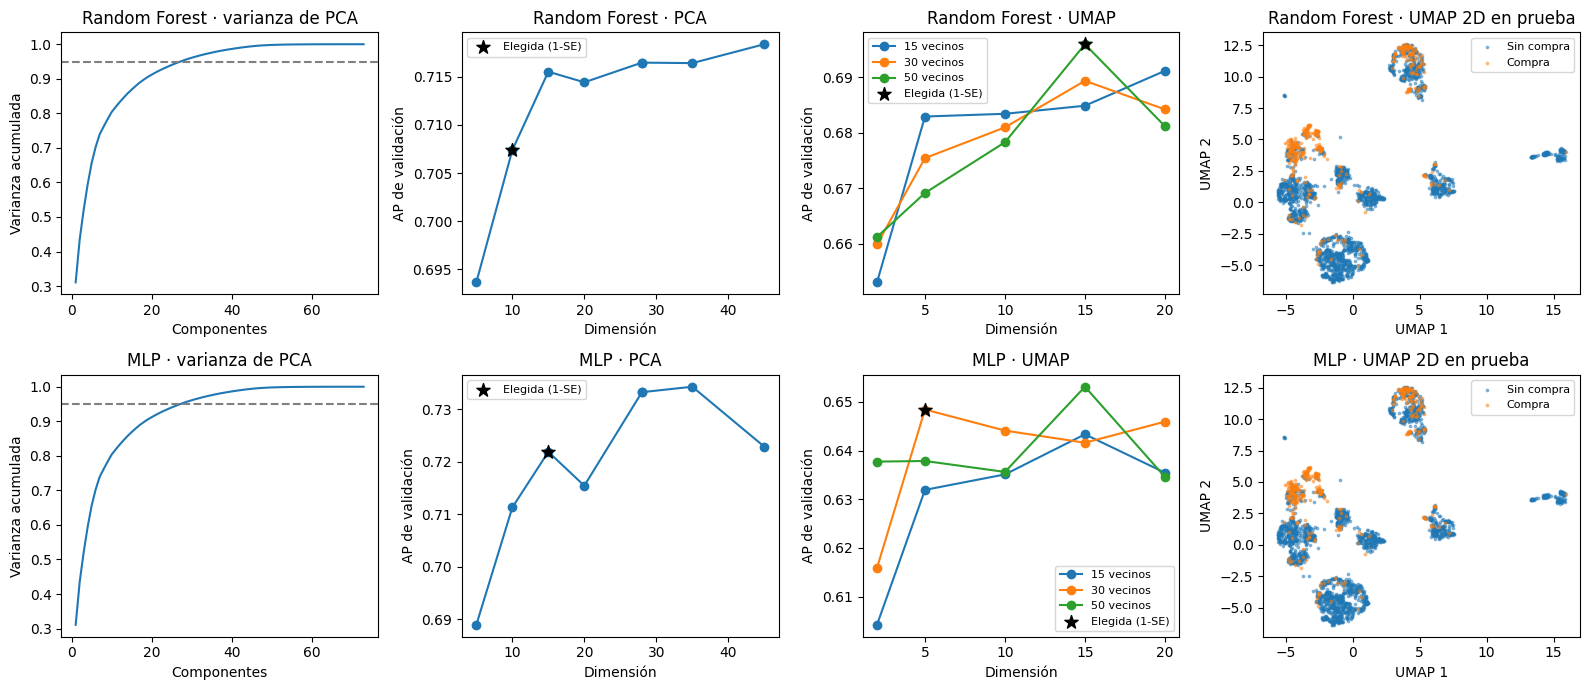

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for familia, (ax_var, ax_pca, ax_umap, ax_2d) in zip(familias[:2], axes):
    nombre = FAMILIAS[familia]
    curva = varianza.query("modelo == @familia")
    ax_var.plot(curva.componente, curva.varianza_acumulada)
    ax_var.axhline(.95, ls="--", color="gray")
    ax_var.set(title=f"{nombre} · varianza de PCA", xlabel="Componentes", ylabel="Varianza acumulada")

    candidatos = barrido.query("modelo == @familia")
    pca = candidatos.query("metodo == 'PCA'").sort_values("componentes")
    ax_pca.plot(pca.componentes, pca.AP, "o-")
    for k, grupo in candidatos.query("metodo == 'UMAP'").groupby("vecinos"):
        grupo = grupo.sort_values("componentes")
        ax_umap.plot(grupo.componentes, grupo.AP, "o-", label=f"{k:g} vecinos")
    for metodo, ax in [("PCA", ax_pca), ("UMAP", ax_umap)]:
        elegido = elegidos.query("modelo == @familia and metodo == @metodo")
        ax.scatter(elegido.componentes, elegido.AP, marker="*", color="black", s=100, zorder=3,
                   label="Elegida (1-SE)")
        ax.set(title=f"{nombre} · {metodo}", xlabel="Dimensión", ylabel="AP de validación")
        ax.legend(fontsize=8)

    for compra, grupo in proyeccion.query("modelo == @familia").groupby("compra"):
        ax_2d.scatter(grupo.x, grupo.y, s=3, alpha=.45, label="Compra" if compra else "Sin compra")
    ax_2d.set(title=f"{nombre} · UMAP 2D en prueba", xlabel="UMAP 1", ylabel="UMAP 2")
    ax_2d.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Evaluación de las variantes fijadas

En prueba comparamos la base de 73 columnas, la variante elegida de cada método y
la proyección UMAP 2D. La primera tabla da, para cada variante, el número de
componentes y el porcentaje de reducción, calculado como $1 - k/73$. También
muestra el AP de validación con el que se eligió la variante y las métricas de
prueba con su intervalo bootstrap. La última columna es la diferencia pareada de
AP frente a la base sobre las mismas sesiones. La segunda tabla agrega la misma
diferencia para ROC-AUC.

In [14]:
diferencias = pd.concat(
    [comparar(muestra, muestras[familia, te]).assign(modelo=familia, metodo=metodo)
     for (familia, metodo), muestra in muestras_reducidas.items()],
    ignore_index=True,
)
filas = []
for familia in familias[:2]:
    variantes = [("Base", n_base, metricas.at[(familia, va), "AP"])]
    variantes += [(v.metodo, v.componentes, v.AP_validacion)
                  for v in ajustes.query("modelo == @familia").itertuples()]
    for metodo, componentes, ap_validacion in variantes:
        muestra = muestras[familia, te] if metodo == "Base" else muestras_reducidas[familia, metodo]
        ic = intervalos(muestra).set_index("metrica")
        delta = diferencias.query("modelo == @familia and metodo == @metodo and metrica == 'AP'")
        filas.append({
            "modelo": familia,
            "metodo": metodo,
            "Componentes": int(componentes),
            "Reducción (%)": round(100 * (1 - componentes / n_base), 1),
            "AP validación": round(ap_validacion, 4),
            "AP prueba [IC 95 %]": con_ic(muestra.AP.iloc[0], *ic.loc["AP", ["ic_inferior", "ic_superior"]]),
            "ROC-AUC prueba": round(muestra.ROC_AUC.iloc[0], 4),
            "F1 prueba": round(muestra.F1.iloc[0], 4),
            "ΔAP frente a la base [IC 95 %]": "—" if delta.empty else con_ic(
                *delta[["diferencia_puntual", "ic_inferior", "ic_superior"]].iloc[0], signo="+"),
        })
mostrar(pd.DataFrame(filas).set_index(["modelo", "metodo"]))
mostrar(diferencias.set_index(["modelo", "metodo", "metrica"])
        [["diferencia_puntual", "ic_inferior", "ic_superior"]].round(4))

Componentes  Reducción (%)  AP validación  \
Modelo        Método                                               
Random Forest Base              73            0.0         0.7414   
              PCA               10           86.3         0.7074   
              UMAP              15           79.5         0.6959   
              UMAP 2D            2           97.3         0.6531   
MLP           Base              73            0.0         0.7225   
              PCA               15           79.5         0.7219   
              UMAP               5           93.2         0.6484   
              UMAP 2D            2           97.3         0.6042   

                           AP prueba [IC 95 %]  ROC-AUC prueba  F1 prueba  \
Modelo        Método                                                        
Random Forest Base     0.7496 [0.7134, 0.7869]          0.9302     0.6608   
              PCA      0.7236 [0.6831, 0.7626]          0.9134     0.6145   
              UMAP     0.6841 [0.6423, 0.7257]          0.8906     0.5826   
              UMAP 2D  0.6443 [0.6007, 0.6881]          0.8850     0.5452   
MLP           Base     0.7494 [0.7127, 0.7873]          0.9284     0.6446   
              PCA      0.7408 [0.7027, 0.7803]          0.9255     0.6424   
              UMAP     0.6365 [0.5947, 0.6809]          0.8611     0.5429   
              UMAP 2D  0.5621 [0.5172, 0.6181]          0.8531     0.5320   

                      ΔAP frente a la base [IC 95 %]  
Modelo        Método                                  
Random Forest Base                                 —  
              PCA         -0.0260 [-0.0438, -0.0090]  
              UMAP        -0.0655 [-0.0937, -0.0377]  
              UMAP 2D     -0.1053 [-0.1365, -0.0740]  
MLP           Base                                 —  
              PCA         -0.0086 [-0.0219, +0.0050]  
              UMAP        -0.1129 [-0.1428, -0.0830]  
              UMAP 2D     -0.1873 [-0.2242, -0.1428]

Diferencia  IC inferior  IC superior
Modelo        Método  Métrica                                      
MLP           PCA     AP          -0.0086      -0.0219       0.0050
                      ROC-AUC     -0.0029      -0.0084       0.0030
              UMAP    AP          -0.1129      -0.1428      -0.0830
                      ROC-AUC     -0.0673      -0.0824      -0.0519
Random Forest PCA     AP          -0.0260      -0.0438      -0.0090
                      ROC-AUC     -0.0167      -0.0246      -0.0093
              UMAP    AP          -0.0655      -0.0937      -0.0377
                      ROC-AUC     -0.0396      -0.0521      -0.0277
              UMAP 2D AP          -0.1053      -0.1365      -0.0740
                      ROC-AUC     -0.0451      -0.0586      -0.0325
MLP           UMAP 2D AP          -0.1873      -0.2242      -0.1428
                      ROC-AUC     -0.0753      -0.0908      -0.0597

## 6. Discusión y conclusiones

### Qué modelo elegir

Random Forest gana la regla de selección fijada de antemano, con una AP de
0,7414 en validación y de 0,7496 en prueba. La MLP queda segunda en validación
(0,7225) y prácticamente empatada en prueba (0,7494). La comparación pareada en
prueba no detecta diferencia entre las dos en AP (+0,0002, IC [−0,0190; 0,0190])
ni en ROC-AUC (+0,0018, IC [−0,0036; 0,0075]), aunque eso no prueba que sean
iguales. Ambas superan a SVM, k-NN y regresión logística en AP, con intervalos
pareados que excluyen el cero. Entre Random Forest y la MLP, la elección puede
apoyarse en criterios prácticos como la interpretación, el costo de cómputo, la
calibración o el tipo de errores. Sin contar k-NN, cuyo AP de 1 en entrenamiento es un
efecto de ponderar por distancia (cada sesión se encuentra a sí misma), Random
Forest tiene la brecha más amplia entre entrenamiento y validación (0,8284 frente
a 0,7414). Aun así, en prueba generaliza tan bien como la MLP.

### El umbral de decisión

Con el umbral nativo, Random Forest favorece la precisión (0,7443) y deja
escapar cuatro de cada diez compras (recall 0,5942). El umbral elegido por F1 en
validación sube el recall a 0,7356 y el F1 a 0,6904, a costa de bajar la
precisión a 0,6505. En prueba encuentra 54 compras más (281 frente a 227) con
73 falsas alarmas más (151 frente a 78). Cuál de los dos conviene depende del
costo de cada error, que este trabajo no mide.

### De qué depende el modelo

`PageValues` domina. Su AUC individual es 0,866 y, al retirarla y volver a
buscar los hiperparámetros, el AP de validación cae a entre 0,33 y 0,38 en las
cinco familias. Ninguna otra decisión del diseño tiene un efecto comparable. Eso
fija el alcance del trabajo: el modelo sirve para analizar sesiones cerradas y
priorizar acciones posteriores, no para decidir durante la navegación, donde
habría que asumir esa pérdida. `SpecialDay`, en cambio, casi no aporta: retirarla
o codificarla con one-hot cambia el AP de validación en menos de 0,01 en todas
las familias.

### ¿Se puede reducir la complejidad del modelo?

En variables, sí. Retirar las seis variables con AUC individual menor que 0,55
deja a Random Forest con 11 predictores y el mismo AP: +0,0008 en validación y
−0,0007 en validación cruzada. En la MLP, el cambio en validación cruzada
(+0,0038) también está dentro de la variación entre pliegues. Retirar una
variable de cada par redundante, en cambio, le cuesta AP a Random Forest, así
que conviene conservar ambas.

En dimensión, no. Retener el 95 % de la varianza con PCA exige 28 componentes,
más que los 17 predictores originales. Con la regla 1-SE, PCA reduce la
dimensión un 86,3 % en Random Forest (10 componentes) y un 79,5 % en la MLP
(15). En Random Forest cuesta 0,0260 de AP en prueba, con un intervalo que
excluye el cero. En la MLP la pérdida (−0,0086, IC [−0,0219; 0,0050]) no se
distingue de cero, pero tampoco hay ganancia. UMAP pierde más en las dos familias
(−0,0655 y −0,1129), y la proyección en dos dimensiones muestra que las sesiones
con y sin compra se solapan. Ninguna de las dos transformaciones usa la
etiqueta, y no logran concentrar la señal mejor que las variables originales.
Aquí UMAP sirve para visualizar, no para modelar.

**Recomendación.** Random Forest con los 11 predictores, sin reducción de
dimensión y con un umbral fijado según el costo de los errores. Si ese costo no
se conoce, el umbral por F1 en validación es un punto de partida razonable. La
variante con 11 predictores solo se comparó en validación, así que antes de
adoptarla habría que confirmar su desempeño en una partición independiente.

### Comparación con los trabajos previos

Nuestras cifras no se pueden comparar directamente con las de la tabla del
notebook 01, porque cada trabajo usa otra partición, sobremuestreo y otras
métricas. Como referencia, nuestro ROC-AUC de prueba (0,9302 con Random Forest)
queda por encima del 0,8973 que Necula (2023) obtiene en prueba con RF y por
debajo del 0,985 de Lin (2025) con CatBoost, que preprocesa antes de partir los
datos. Nuestra exactitud en prueba (0,9045) queda entre el 87,24 % de Sakar et
al. (2019) y el 92,39 % de Satu e Islam (2023), aunque con un 15 % de compras esa
métrica dice poco. Nuestro F1 (0,66 con el umbral nativo y 0,69 con el ajustado)
es menor que los 0,86–0,92 publicados. Esos valores, sin embargo, se obtienen
con sobremuestreo, y no siempre queda claro si corresponden a la clase de compra
o a un promedio entre clases. Lo que este trabajo agrega frente a ellos es el
protocolo: el preprocesamiento dentro de los pliegues, la prueba reservada, y los
intervalos y comparaciones pareadas.

### Limitaciones

- **Una sola base y una sola semilla.** Las particiones son estratificadas, pero
  no temporales. Faltan enero y abril, en febrero la validación no tiene compras,
  y el AP mensual varía entre 0,57 y 0,88, con estimaciones ruidosas en los meses
  con pocas sesiones.
- **Prueba conocida.** La prueba no participó en ninguna decisión de esta
  versión, pero sus métricas se conocían de una entrega anterior, así que las
  leemos como descriptivas y no como una evaluación independiente.
- **Intervalos condicionados.** El bootstrap deja fijos los modelos y sus
  predicciones, de modo que no incluye la variación del entrenamiento ni de la
  selección.
- **Umbral y calibración.** No calibramos las probabilidades, y el umbral se
  eligió por F1, que pesa igual la precisión y el recall, no por un análisis de
  costos.
- **Reducción.** PCA y UMAP reciben las numéricas estandarizadas y las
  indicadoras 0/1 sin escalar, y UMAP depende de su inicialización.

Como trabajo futuro proponemos una validación temporal, calibrar las
probabilidades, elegir el umbral según el costo de los errores y repetir el
protocolo con otras semillas.

## Referencias

- B. Efron, «Bootstrap methods: Another look at the jackknife», *The Annals of
  Statistics*, vol. 7, n.º 1, pp. 1–26, 1979.
  [doi:10.1214/aos/1176344552](https://doi.org/10.1214/aos/1176344552)
- L. McInnes, J. Healy, N. Saul y L. Großberger, «UMAP: Uniform Manifold
  Approximation and Projection», *Journal of Open Source Software*, vol. 3,
  n.º 29, art. 861, 2018. [doi:10.21105/joss.00861](https://doi.org/10.21105/joss.00861)
- Y. Chen e Y. Yang, «The one standard error rule for model selection: Does it
  work?», *Stats*, vol. 4, n.º 4, pp. 868–892, 2021.
  [doi:10.3390/stats4040051](https://doi.org/10.3390/stats4040051)

Las referencias del conjunto de datos y de los trabajos previos están en el
estado del arte del notebook 01.